# Grupo D — Exportações marítimas de Itajaí e contêineres cheios

Miguel Pezzini Kuhr e Jordan Lippert.

**Pergunta.** Quanto da oscilação mensal do número de contêineres cheios embarcados no Complexo de Itajaí pode ser antecipada com as exportações marítimas já declaradas em Itajaí?

**Tarefa.** Prever os contêineres cheios de um mês X usando só dados até X−1 (contêineres e peso líquido de X−1). Na M3, compara-se a regra “X repete os contêineres de X−1” com o peso líquido de X−1.

Esta entrega é a análise exploratória (M2.2). O notebook monta o painel mensal, descreve a cobertura e a associação, e não treina modelo. A comparação de erro de previsão fica para a M3. Os seis últimos meses em que as duas defasagens existem ficam reservados para esse teste e não são usados para mudar filtro.

Localmente os arquivos estão em `dados/antaq/{ano}/` e `dados/EXP_{ano}.csv`, com os dicionários em `dados/dicionarios/`. No Kaggle, o conjunto precisa de `antaq/{ano}/{ano}Atracacao.txt`, `antaq/{ano}/{ano}Carga.txt`, `comex/EXP_{ano}.csv` e `dicionarios/`. A célula seguinte aponta para `/kaggle/input` quando essa pasta existe.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

def achar_entrada_kaggle():
    raiz = Path("/kaggle/input")
    candidatos = [p for p in raiz.iterdir() if p.is_dir()]
    if not candidatos:
        raise FileNotFoundError("Nenhum conjunto em /kaggle/input")
    return candidatos[0]

if Path("/kaggle/input").exists():
    BASE = achar_entrada_kaggle()
    ANTAQ_ROOT = BASE / "antaq" if (BASE / "antaq").exists() else BASE
    COMEX_DIR = BASE / "comex" if (BASE / "comex").exists() else BASE
    DICT_DIR = BASE / "dicionarios" if (BASE / "dicionarios").exists() else BASE
    OUT_DIR = Path("/kaggle/working")
    ENTREGA = OUT_DIR
else:
    RAIZ = Path("/home/miguel/Programming/IA-M2-M3")
    ANTAQ_ROOT = RAIZ / "dados" / "antaq"
    COMEX_DIR = RAIZ / "dados"
    DICT_DIR = COMEX_DIR / "dicionarios"
    OUT_DIR = RAIZ / "outputs"
    ENTREGA = RAIZ

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "figuras").mkdir(exist_ok=True)
print("ANTAQ:", ANTAQ_ROOT)
print("Comex:", COMEX_DIR)
print("saída:", OUT_DIR)
print("pandas", pd.__version__)


ANTAQ: /home/miguel/Programming/IA-M2-M3/dados/antaq
Comex: /home/miguel/Programming/IA-M2-M3/dados
saída: /home/miguel/Programming/IA-M2-M3/outputs
pandas 3.1.0


## Definições fixadas antes de olhar a associação

O alvo é a soma de `QTCarga` no Complexo Portuário Itajaí, com natureza carga conteinerizada, estado cheio, sentido embarcados, `FlagAutorizacao` = S, `FlagMCOperacaoCarga` = 1 e navegação de longo curso. O mês é o `Ano`/`Mes` da atracação, que na documentação da ANTAQ segue a desatracação. Portonave entra nesse complexo. Itapoá fica de fora.

A outra grandeza é a soma de `KG_LIQUIDO` no Comex Stat, URF `0927800` e via `01` (marítima). `VL_FOB` é somado só para constar no painel. `QT_ESTAT` não é somado, porque a unidade muda com o NCM.

Um mês sem arquivo não vira zero. Zero é um mês coberto em que a soma do recorte é nula. A defasagem olha o mês civil anterior, não a observação anterior da tabela.


## Dicionário de variáveis

A unidade é a da grandeza medida. Código, texto e indicador não têm unidade física. `QT_ESTAT` muda com o NCM e por isso não é somada.

### ANTAQ — atracação

| Variável | Descrição | Unidade |
|---|---|---|
| `IDAtracacao` | Identificador da atracação. Liga cada item de carga ao mês e ao porto. | — |
| `Complexo Portuário` | Complexo em que o navio atracou. O recorte fica em Itajaí. | — |
| `Porto Atracação` | Terminal da atracação. Portonave entra nesse complexo. Itapoá fica de fora. | — |
| `Ano` | Ano da desatracação. | ano |
| `Mes` | Mês da desatracação, abreviado (`jan` a `dez`). | mês |

### ANTAQ — carga

| Variável | Descrição | Unidade |
|---|---|---|
| `IDCarga` | Identificador do item de carga. | — |
| `Natureza da Carga` | Classificação da carga. O alvo usa carga conteinerizada. | — |
| `ConteinerEstado` | Estado do contêiner. O alvo usa cheio. | — |
| `Sentido` | Sentido da movimentação. O alvo usa embarcados. | — |
| `Tipo Navegação` | Tipo de navegação. O alvo usa longo curso. A cabotagem só entra na comparação. | — |
| `FlagAutorizacao` | Carga autorizada. O alvo exige `S`. | — |
| `FlagMCOperacaoCarga` | Houve movimentação de carga. O alvo exige `1`. | — |
| `QTCarga` | Quantidade do item. No recorte conteinerizado, a soma mensal é o número de contêineres. | contêiner |

### Comex Stat — exportação

| Variável | Descrição | Unidade |
|---|---|---|
| `CO_ANO` | Ano da declaração de exportação. | ano |
| `CO_MES` | Mês da declaração (`01` a `12`). | mês |
| `CO_NCM` | Código NCM do produto, com oito dígitos. | — |
| `CO_UNID` | Código da unidade estatística daquele NCM. | — |
| `CO_PAIS` | Código do país de destino. | — |
| `SG_UF_NCM` | Sigla da UF do produtor. | — |
| `CO_VIA` | Via de transporte. O recorte usa `01` (marítima). | — |
| `CO_URF` | Unidade da Receita do despacho. O recorte usa `0927800` (Itajaí). | — |
| `QT_ESTAT` | Quantidade na unidade estatística do NCM. Não é somada. | varia com o NCM (kg, un, m, …) |
| `KG_LIQUIDO` | Peso líquido declarado. É a grandeza somada no recorte. | kg |
| `VL_FOB` | Valor FOB. Vai para o painel e não entra nas perguntas. | US$ |

### Painel mensal

Uma linha é um mês civil. Mês sem arquivo fica ausente, não zero. A defasagem é o mês civil anterior.

| Variável | Descrição | Unidade |
|---|---|---|
| `data` | Primeiro dia do mês. | data |
| `ano` | Ano do mês. | ano |
| `mes` | Número do mês, de 1 a 12. | mês |
| `mes_rotulo` | Rótulo `AAAA-MM`. | — |
| `conteineres` | Soma de `QTCarga` no alvo (longo curso). É o alvo da análise. | contêiner |
| `conteineres_cabotagem` | Mesmo filtro, com navegação de cabotagem. | contêiner |
| `conteineres_lag1` | `conteineres` do mês civil anterior. | contêiner |
| `kg_liquido` | Soma de `KG_LIQUIDO` na URF de Itajaí e via marítima. | kg |
| `kg_lag1` | `kg_liquido` do mês civil anterior. | kg |
| `vl_fob` | Soma de `VL_FOB` no mesmo recorte do Comex. | US$ |


In [2]:
MES_MAP = {
    "jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6,
    "jul": 7, "ago": 8, "set": 9, "out": 10, "nov": 11, "dez": 12,
}
COLS_ATR = ["IDAtracacao", "Complexo Portuário", "Ano", "Mes", "Porto Atracação"]
COLS_CARGA = [
    "IDCarga", "IDAtracacao", "Natureza da Carga", "ConteinerEstado", "Sentido",
    "Tipo Navegação", "FlagAutorizacao", "FlagMCOperacaoCarga", "QTCarga",
]
COLS_EXP = [
    "CO_ANO", "CO_MES", "CO_NCM", "CO_UNID", "CO_PAIS", "SG_UF_NCM",
    "CO_VIA", "CO_URF", "QT_ESTAT", "KG_LIQUIDO", "VL_FOB",
]

def parse_numero(serie):
    s = serie.fillna("").astype(str).str.strip()
    com_virgula = s.str.contains(",", regex=False)
    convertido = s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    s = s.where(~com_virgula, convertido)
    s = s.replace({"": "0"})
    return pd.to_numeric(s, errors="coerce").fillna(0.0)

def anos_antaq(raiz):
    achados = []
    for pasta in sorted(p for p in raiz.iterdir() if p.is_dir() and p.name.isdigit()):
        ano = pasta.name
        if (pasta / f"{ano}Atracacao.txt").exists() and (pasta / f"{ano}Carga.txt").exists():
            achados.append(int(ano))
    return achados

def rotulo(data):
    return f"{data.year:04d}-{data.month:02d}"

def pearson(df, a, b):
    sub = df[[a, b]].dropna()
    if len(sub) < 3 or sub[a].nunique() < 2 or sub[b].nunique() < 2:
        return len(sub), None
    return len(sub), float(sub[a].corr(sub[b]))

def fmt_int(n):
    return f"{int(n):,}".replace(",", ".")

def fmt_r(r):
    if r is None:
        return "indefinida"
    return f"{r:.2f}".replace(".", ",")


In [3]:
anos = anos_antaq(ANTAQ_ROOT)
print("Anos ANTAQ encontrados:", anos)
if not anos:
    raise FileNotFoundError(f"Nenhum par Atracacao/Carga em {ANTAQ_ROOT}")

por_ano = {}
n_atr_itajai = 0
n_atr_id_duplicado = 0
for ano in anos:
    pasta = ANTAQ_ROOT / str(ano)
    atr = pd.read_csv(pasta / f"{ano}Atracacao.txt", sep=";", encoding="utf-8-sig", dtype=str, usecols=COLS_ATR)
    atr["Complexo Portuário"] = atr["Complexo Portuário"].fillna("").str.strip()
    it = atr[atr["Complexo Portuário"] == "Itajaí"].copy()
    it["ano"] = pd.to_numeric(it["Ano"], errors="coerce")
    it["mes"] = it["Mes"].fillna("").str.strip().str.lower().map(MES_MAP)
    ruins = it.loc[it["mes"].isna() | it["ano"].isna(), "Mes"].unique().tolist()
    if ruins:
        raise ValueError(f"Mês não mapeado em {ano}: {ruins[:8]}")
    it["ano"] = it["ano"].astype(int)
    it["mes"] = it["mes"].astype(int)
    n_atr_itajai += len(it)
    n_atr_id_duplicado += int(it["IDAtracacao"].duplicated().sum())
    por_ano[ano] = it[["IDAtracacao", "ano", "mes", "Porto Atracação", "Complexo Portuário"]]
    print(f"  {ano}: {len(it)} atracações no complexo, meses {sorted(int(m) for m in it['mes'].unique())}")

atr_ok = pd.concat(por_ano.values(), ignore_index=True)
atr_ok = atr_ok.drop_duplicates("IDAtracacao")
meta = atr_ok.set_index("IDAtracacao")

n_carga_lidas = 0
n_carga_complexo = 0
n_idcarga_duplicado = 0
n_alvo = 0
n_cabo = 0
n_dup_alvo = 0
vistos = set()
vistos_alvo = set()
soma_longo = {}
soma_cabo = {}
amostras_a = []

for ano in anos:
    pasta = ANTAQ_ROOT / str(ano)
    ids = set(por_ano[ano]["IDAtracacao"])
    leitor = pd.read_csv(
        pasta / f"{ano}Carga.txt",
        sep=";",
        encoding="utf-8-sig",
        dtype=str,
        usecols=COLS_CARGA,
        chunksize=300_000,
    )
    lidas_ano = 0
    complexo_ano = 0
    alvo_ano = 0
    for bloco in leitor:
        n_carga_lidas += len(bloco)
        lidas_ano += len(bloco)
        sub = bloco[bloco["IDAtracacao"].isin(ids)]
        if sub.empty:
            continue
        n_carga_complexo += len(sub)
        complexo_ano += len(sub)
        for ident in sub["IDCarga"]:
            if ident in vistos:
                n_idcarga_duplicado += 1
            else:
                vistos.add(ident)
        nat = sub["Natureza da Carga"].fillna("").str.strip()
        est = sub["ConteinerEstado"].fillna("").str.strip()
        sen = sub["Sentido"].fillna("").str.strip()
        nav = sub["Tipo Navegação"].fillna("").str.strip()
        flag_a = sub["FlagAutorizacao"].fillna("").str.strip()
        flag_m = sub["FlagMCOperacaoCarga"].fillna("").str.strip()
        base = (
            (nat == "Carga Conteinerizada")
            & (est == "Cheio")
            & (sen == "Embarcados")
            & (flag_a == "S")
            & (flag_m == "1")
        )
        longo = sub.loc[base & (nav == "Longo Curso")].copy()
        cabo = sub.loc[base & (nav == "Cabotagem")].copy()
        n_alvo += len(longo)
        n_cabo += len(cabo)
        alvo_ano += len(longo)
        for ident in longo["IDCarga"]:
            if ident in vistos_alvo:
                n_dup_alvo += 1
            else:
                vistos_alvo.add(ident)
        for pedaco, destino in ((longo, soma_longo), (cabo, soma_cabo)):
            if pedaco.empty:
                continue
            pedaco = pedaco.join(meta[["ano", "mes"]], on="IDAtracacao")
            pedaco["qt"] = parse_numero(pedaco["QTCarga"])
            for (a, m), valor in pedaco.groupby(["ano", "mes"])["qt"].sum().items():
                chave = (int(a), int(m))
                destino[chave] = destino.get(chave, 0.0) + float(valor)
        if len(amostras_a) < 8 and not longo.empty:
            pedaco = longo.join(meta[["ano", "mes", "Porto Atracação", "Complexo Portuário"]], on="IDAtracacao")
            for _, linha in pedaco.head(8 - len(amostras_a)).iterrows():
                amostras_a.append({
                    "IDCarga": linha["IDCarga"],
                    "IDAtracacao": linha["IDAtracacao"],
                    "Ano": int(linha["ano"]),
                    "Mes": int(linha["mes"]),
                    "Complexo Portuário": linha["Complexo Portuário"],
                    "Porto Atracação": linha["Porto Atracação"],
                    "Natureza da Carga": linha["Natureza da Carga"],
                    "ConteinerEstado": linha["ConteinerEstado"],
                    "Sentido": linha["Sentido"],
                    "Tipo Navegação": linha["Tipo Navegação"],
                    "FlagAutorizacao": linha["FlagAutorizacao"],
                    "FlagMCOperacaoCarga": linha["FlagMCOperacaoCarga"],
                    "QTCarga": linha["QTCarga"],
                })
    print(f"  carga {ano}: {fmt_int(lidas_ano)} linhas lidas, {fmt_int(complexo_ano)} no complexo, {fmt_int(alvo_ano)} no alvo")
    if complexo_ano > 0 and alvo_ano == 0:
        raise RuntimeError(f"Ano {ano} tem carga no complexo e nenhum contêiner no recorte. Conferir rótulos.")

cobertura_antaq = (
    atr_ok[["ano", "mes"]]
    .drop_duplicates()
    .sort_values(["ano", "mes"])
)
somas_antaq = pd.DataFrame(
    [{"ano": a, "mes": m, "conteineres": soma_longo.get((a, m), 0.0),
      "conteineres_cabotagem": soma_cabo.get((a, m), 0.0)}
     for a, m in cobertura_antaq.itertuples(index=False, name=None)]
)
print("Itens de carga no alvo (longo curso):", fmt_int(n_alvo))
print("Itens de carga na cabotagem, mesmo restante do filtro:", fmt_int(n_cabo))


Anos ANTAQ encontrados: [2023, 2024, 2025, 2026]
  2023: 924 atracações no complexo, meses [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


  2024: 833 atracações no complexo, meses [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
  2025: 563 atracações no complexo, meses [1, 2, 3, 4, 5, 6]
  2026: 217 atracações no complexo, meses [1, 2]


  carga 2023: 2.200.645 linhas lidas, 724.195 no complexo, 212.108 no alvo


  carga 2024: 2.437.573 linhas lidas, 680.141 no complexo, 134.972 no alvo


  carga 2025: 1.193.207 linhas lidas, 284.419 no complexo, 50.489 no alvo


  carga 2026: 389.935 linhas lidas, 110.302 no complexo, 20.111 no alvo
Itens de carga no alvo (longo curso): 417.680
Itens de carga na cabotagem, mesmo restante do filtro: 111.689


In [4]:
arquivos_exp = sorted(COMEX_DIR.glob("EXP_*.csv"))
if not arquivos_exp:
    raise FileNotFoundError(f"Nenhum EXP_*.csv em {COMEX_DIR}")

n_comex_lidas = 0
n_comex_recorte = 0
soma_kg = {}
soma_fob = {}
meses_comex = set()
amostras_b = []

for caminho in arquivos_exp:
    lidas = 0
    recorte = 0
    leitor = pd.read_csv(caminho, sep=";", dtype=str, encoding="latin-1", usecols=COLS_EXP, chunksize=400_000)
    for bloco in leitor:
        n_comex_lidas += len(bloco)
        lidas += len(bloco)
        bloco["CO_ANO"] = bloco["CO_ANO"].str.strip()
        bloco["CO_MES"] = bloco["CO_MES"].str.strip()
        for par in bloco.groupby(["CO_ANO", "CO_MES"]).size().index:
            meses_comex.add((int(par[0]), int(par[1])))
        mask = (bloco["CO_URF"].str.strip() == "0927800") & (bloco["CO_VIA"].str.strip() == "01")
        rec = bloco.loc[mask].copy()
        if rec.empty:
            continue
        n_comex_recorte += len(rec)
        recorte += len(rec)
        rec["ano"] = rec["CO_ANO"].astype(int)
        rec["mes"] = rec["CO_MES"].astype(int)
        rec["kg"] = pd.to_numeric(rec["KG_LIQUIDO"], errors="coerce").fillna(0.0)
        rec["fob"] = pd.to_numeric(rec["VL_FOB"], errors="coerce").fillna(0.0)
        for (a, m), grupo in rec.groupby(["ano", "mes"]):
            chave = (int(a), int(m))
            soma_kg[chave] = soma_kg.get(chave, 0.0) + float(grupo["kg"].sum())
            soma_fob[chave] = soma_fob.get(chave, 0.0) + float(grupo["fob"].sum())
        if len(amostras_b) < 8:
            amostras_b.extend(rec.head(8 - len(amostras_b))[COLS_EXP].to_dict("records"))
    print(f"  {caminho.name}: {fmt_int(lidas)} linhas, {fmt_int(recorte)} no recorte")

urf = pd.read_csv(DICT_DIR / "URF.csv", sep=";", dtype=str, encoding="latin-1")
via = pd.read_csv(DICT_DIR / "VIA.csv", sep=";", dtype=str, encoding="latin-1")
nome_urf = urf.loc[urf["CO_URF"] == "0927800", "NO_URF"]
nome_via = via.loc[via["CO_VIA"] == "01", "NO_VIA"]
print("URF:", nome_urf.iloc[0] if len(nome_urf) else "0927800")
print("Via:", nome_via.iloc[0] if len(nome_via) else "01")
print("Linhas no recorte Comex:", fmt_int(n_comex_recorte))


  EXP_2023.csv: 1.563.659 linhas, 41.903 no recorte


  EXP_2024.csv: 1.603.796 linhas, 28.935 no recorte


  EXP_2025.csv: 1.709.746 linhas, 32.555 no recorte


  EXP_2026.csv: 1.272.295 linhas, 30.448 no recorte
URF: 0927800 - ITAJAI
Via: MARITIMA
Linhas no recorte Comex: 133.841


In [5]:
cobertura_comex = pd.DataFrame(sorted(meses_comex), columns=["ano", "mes"])
chaves_comex = list(zip(cobertura_comex["ano"].astype(int), cobertura_comex["mes"].astype(int)))
somas_comex = cobertura_comex.copy()
somas_comex["kg_liquido"] = [soma_kg.get(chave, 0.0) for chave in chaves_comex]
somas_comex["vl_fob"] = [soma_fob.get(chave, 0.0) for chave in chaves_comex]

antaq_m = somas_antaq.copy()
antaq_m["data"] = pd.to_datetime({"year": antaq_m["ano"], "month": antaq_m["mes"], "day": 1})
comex_m = somas_comex.copy()
comex_m["data"] = pd.to_datetime({"year": comex_m["ano"], "month": comex_m["mes"], "day": 1})

inicio = min(antaq_m["data"].min(), comex_m["data"].min())
fim = max(antaq_m["data"].max(), comex_m["data"].max())
grade = pd.DataFrame({"data": pd.date_range(inicio, fim, freq="MS")})
painel = grade.merge(
    antaq_m[["data", "conteineres", "conteineres_cabotagem"]],
    on="data",
    how="left",
)
painel = painel.merge(comex_m[["data", "kg_liquido", "vl_fob"]], on="data", how="left")
painel["ano"] = painel["data"].dt.year
painel["mes"] = painel["data"].dt.month
painel["conteineres_lag1"] = painel["conteineres"].shift(1)
painel["kg_lag1"] = painel["kg_liquido"].shift(1)
painel["mes_rotulo"] = painel["data"].map(rotulo)

ambos = painel["conteineres"].notna() & painel["kg_liquido"].notna()
so_antaq = painel["conteineres"].notna() & painel["kg_liquido"].isna()
so_comex = painel["kg_liquido"].notna() & painel["conteineres"].isna()
lags = painel["conteineres"].notna() & painel["conteineres_lag1"].notna() & painel["kg_lag1"].notna()

painel.to_csv(OUT_DIR / "painel_mensal.csv", index=False)
print(f"Painel de {rotulo(inicio)} a {rotulo(fim)}: {len(painel)} meses civis")
print("Meses com as duas fontes:", int(ambos.sum()))
print("Só ANTAQ:", painel.loc[so_antaq, "mes_rotulo"].tolist() or "nenhum")
print("Só Comex:", painel.loc[so_comex, "mes_rotulo"].tolist())


Painel de 2023-01 a 2026-09: 45 meses civis
Meses com as duas fontes: 32
Só ANTAQ: nenhum
Só Comex: ['2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']


## Pergunta 1. Quantos meses existem nas duas fontes ao mesmo tempo?

O denominador é o calendário entre o primeiro e o último mês em que alguma das fontes tem arquivo. Um mês conta como coberto quando o arquivo daquele ano traz o mês, mesmo que a soma do recorte seja zero.


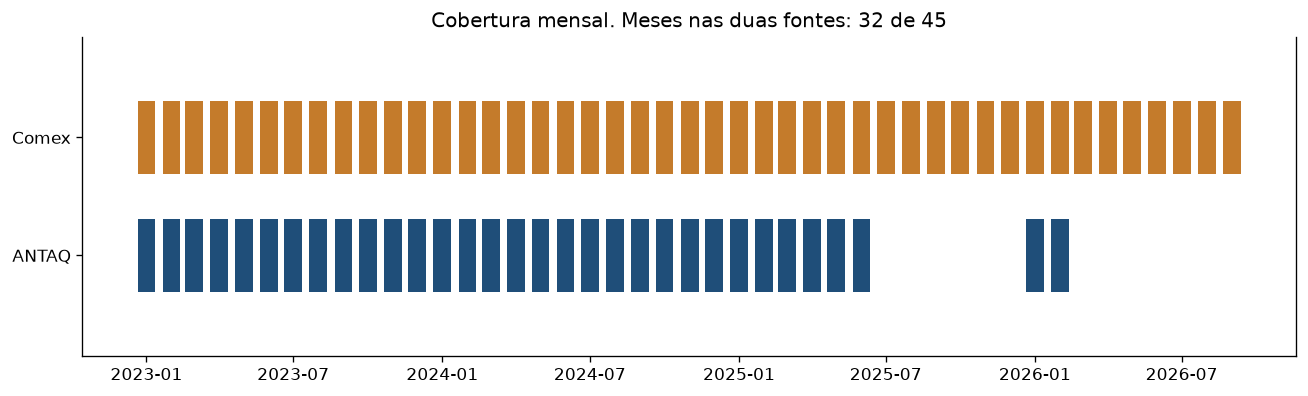

Conclusão. As duas fontes se encontram em 32 meses.
A ANTAQ cobre 32 meses e o Comex cobre 45.
Meses só no Comex ( 13 ): 2025-07, 2025-08, 2025-09, 2025-10, 2025-11, 2025-12, 2026-03, 2026-04, 2026-05, 2026-06, 2026-07, 2026-08, 2026-09
Limite. O arquivo de 2026 da ANTAQ e a cópia de 2025 não fecham o ano civil. Esses meses não foram preenchidos com zero.


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.4))
faixas = (
    (0, "ANTAQ", painel["conteineres"].notna(), "#1f4e79"),
    (1, "Comex", painel["kg_liquido"].notna(), "#c47b2b"),
)
for nivel, _nome, serie, cor in faixas:
    ax.bar(
        painel.loc[serie, "data"],
        height=0.62,
        bottom=nivel - 0.31,
        width=22,
        color=cor,
        align="center",
    )
ax.set_yticks([0, 1], ["ANTAQ", "Comex"])
ax.set_ylim(-0.85, 1.85)
ax.set_title(f"Cobertura mensal. Meses nas duas fontes: {int(ambos.sum())} de {len(painel)}")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "01_cobertura.png", bbox_inches="tight")
plt.show()

print("Conclusão. As duas fontes se encontram em", int(ambos.sum()), "meses.")
print(
    "A ANTAQ cobre",
    int(painel["conteineres"].notna().sum()),
    "meses e o Comex cobre",
    str(int(painel["kg_liquido"].notna().sum())) + ".",
)
print("Meses só no Comex (", int(so_comex.sum()), "):", ", ".join(painel.loc[so_comex, "mes_rotulo"]))
print("Limite. O arquivo de 2026 da ANTAQ e a cópia de 2025 não fecham o ano civil. Esses meses não foram preenchidos com zero.")


## Pergunta 2. No mesmo mês, o peso exportado e os contêineres cheios andam juntos?

A conta usa apenas os meses em que as duas somas existem. Outubro de 2023 fica marcado quando está nessa interseção. Associação no mesmo mês não é a previsão com um mês de antecedência.


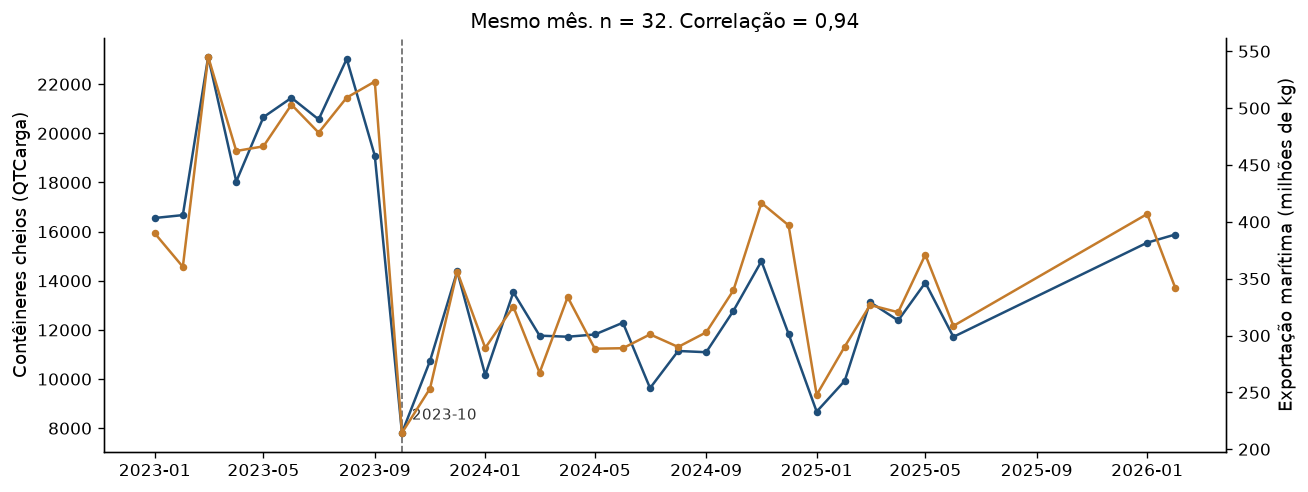

Conclusão. Nos 32 meses em comum, a correlação linear entre contêineres e kg do mesmo mês é 0,94.
Outubro de 2023 tem 7.811 contêineres e 214 milhões de kg. A mediana dos contêineres nesses meses é 12.952.
A cabotagem, fora do alvo, soma 126.745 contêineres cheios embarcados nos mesmos meses.
Ela representa 21.8% da soma cabotagem + longo curso.
Limite. O gráfico descreve o mesmo mês. A pergunta do projeto usa o kg do mês anterior.


In [7]:
contemporaneo = painel.loc[ambos].copy()
n_cont, r_cont = pearson(contemporaneo, "conteineres", "kg_liquido")

fig, ax1 = plt.subplots(figsize=(11, 4.2))
ax1.plot(contemporaneo["data"], contemporaneo["conteineres"], color="#1f4e79", marker="o", ms=3.5, label="Contêineres cheios")
ax1.set_ylabel("Contêineres cheios (QTCarga)")
ax2 = ax1.twinx()
ax2.plot(contemporaneo["data"], contemporaneo["kg_liquido"] / 1e6, color="#c47b2b", marker="o", ms=3.5, label="Kg líquido")
ax2.set_ylabel("Exportação marítima (milhões de kg)")
outubro = contemporaneo.loc[contemporaneo["mes_rotulo"] == "2023-10"]
if len(outubro):
    ax1.axvline(outubro["data"].iloc[0], color="#666666", ls="--", lw=1)
    ax1.annotate("2023-10", (outubro["data"].iloc[0], outubro["conteineres"].iloc[0]),
                 textcoords="offset points", xytext=(6, 8), fontsize=9, color="#333333")
ax1.set_title(f"Mesmo mês. n = {n_cont}. Correlação = {fmt_r(r_cont)}")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "02_mesmo_mes.png", bbox_inches="tight")
plt.show()

total_longo = float(contemporaneo["conteineres"].sum())
total_cabo = float(contemporaneo["conteineres_cabotagem"].sum())
parcela_cabo = total_cabo / (total_longo + total_cabo) if (total_longo + total_cabo) else None
print(f"Conclusão. Nos {n_cont} meses em comum, a correlação linear entre contêineres e kg do mesmo mês é {fmt_r(r_cont)}.")
if len(outubro):
    med = float(contemporaneo["conteineres"].median())
    print(
        f"Outubro de 2023 tem {fmt_int(outubro['conteineres'].iloc[0])} contêineres e "
        f"{outubro['kg_liquido'].iloc[0] / 1e6:.0f} milhões de kg. A mediana dos contêineres nesses meses é {fmt_int(med)}."
    )
print("A cabotagem, fora do alvo, soma", fmt_int(total_cabo), "contêineres cheios embarcados nos mesmos meses.")
if parcela_cabo is not None:
    print(f"Ela representa {100 * parcela_cabo:.1f}% da soma cabotagem + longo curso.")
print("Limite. O gráfico descreve o mesmo mês. A pergunta do projeto usa o kg do mês anterior.")


## Pergunta 3. Como o mês X se dispõe frente a X−1?

Entram os meses em que existem, ao mesmo tempo, os contêineres de X, os contêineres de X−1 e o kg de X−1. As duas correlações descrevem essa nuvem. Elas não são o erro de previsão. Os seis últimos meses dessa lista ficam reservados para a M3 e não alteram os filtros.


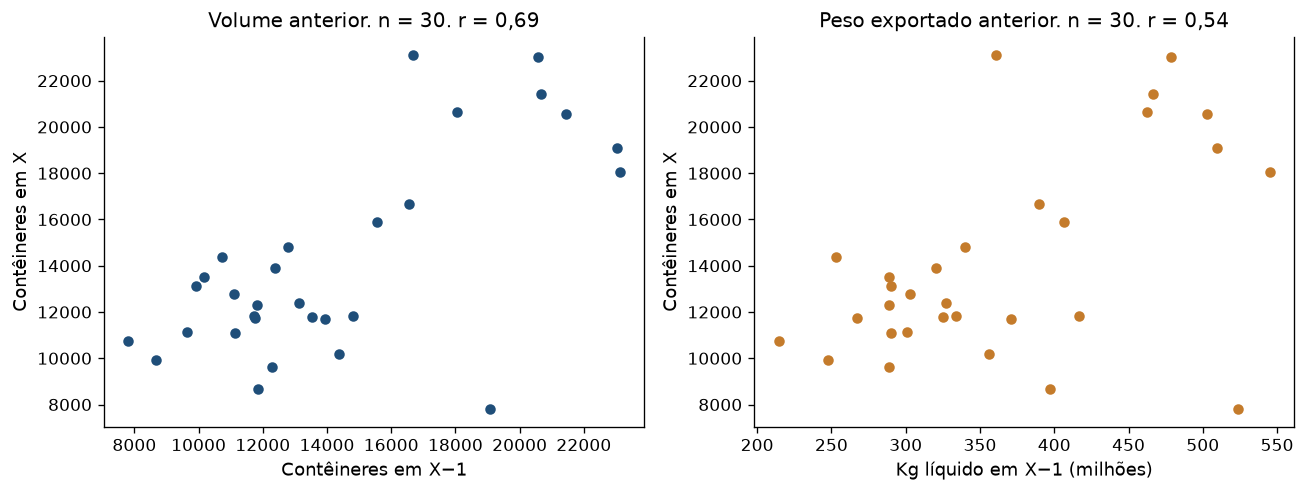

Conclusão. Em 30 meses, a correlação de X com os contêineres de X−1 é 0,69.
A correlação de X com o kg de X−1 é 0,54.
Limite. Correlação na amostra inteira não decide qual regra erra menos. A M3 mede o erro nos meses: 2025-02, 2025-03, 2025-04, 2025-05, 2025-06, 2026-02
Esses meses permanecem nos gráficos. Nenhum filtro foi escolhido para melhorar um resultado deles.


In [8]:
pares = painel.loc[lags].copy()
n_pers, r_pers = pearson(pares, "conteineres", "conteineres_lag1")
n_kg, r_kg = pearson(pares, "conteineres", "kg_lag1")
teste_m3 = pares["mes_rotulo"].tail(6).tolist()

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
eixos[0].scatter(pares["conteineres_lag1"], pares["conteineres"], color="#1f4e79", s=28)
eixos[0].set_xlabel("Contêineres em X−1")
eixos[0].set_ylabel("Contêineres em X")
eixos[0].set_title(f"Volume anterior. n = {n_pers}. r = {fmt_r(r_pers)}")
eixos[1].scatter(pares["kg_lag1"] / 1e6, pares["conteineres"], color="#c47b2b", s=28)
eixos[1].set_xlabel("Kg líquido em X−1 (milhões)")
eixos[1].set_ylabel("Contêineres em X")
eixos[1].set_title(f"Peso exportado anterior. n = {n_kg}. r = {fmt_r(r_kg)}")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "03_defasagem.png", bbox_inches="tight")
plt.show()

print(f"Conclusão. Em {len(pares)} meses, a correlação de X com os contêineres de X−1 é {fmt_r(r_pers)}.")
print(f"A correlação de X com o kg de X−1 é {fmt_r(r_kg)}.")
print("Limite. Correlação na amostra inteira não decide qual regra erra menos. A M3 mede o erro nos meses:", ", ".join(teste_m3))
print("Esses meses permanecem nos gráficos. Nenhum filtro foi escolhido para melhorar um resultado deles.")


## Qualidade da junção e distribuição do alvo

`IDCarga` é a chave do item de carga. `IDAtracacao` se repete porque uma atracação tem vários itens: isso é a cardinalidade esperada, não duplicidade da atracação. No Comex, o mês também se repete, uma vez por NCM. Depois da soma, cada mês aparece uma vez.

O alvo da futura regressão é `conteineres` nos meses cobertos pela ANTAQ. Outubro de 2023, se for baixo, permanece na série.


,Etapa,Linhas,Chaves repetidas,Sem correspondência
0,"Fonte A, carga do complexo",1799057,0,não se aplica
1,"Fonte A, recorte do alvo",417680,0,não se aplica
2,"Fonte B, recorte URF e via",133841,133796,não se aplica
3,Mês nas duas fontes,32,0,13


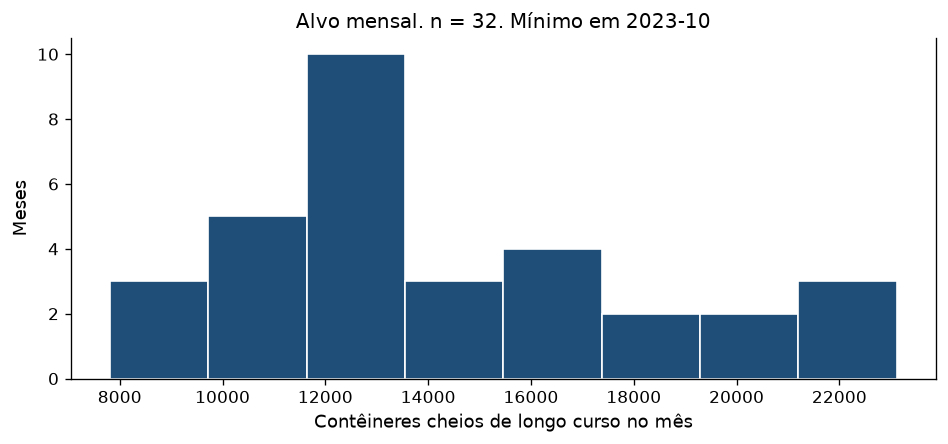

Atracações do complexo: 2.537. IDAtracacao repetido dentro do complexo: 0.
Linhas de carga lidas, todos os portos: 6.221.360.
Linhas de Comex lidas: 6.149.496.
Alvo mensal: n = 32, mínimo = 7.811 em 2023-10, mediana = 12.952, máximo = 23.115.
Outubro de 2023 permanece na série. O mês coincide com as cheias que interromperam o complexo; o valor baixo não foi removido.
VL_FOB está no painel e não entra nas três perguntas. QT_ESTAT não foi somado.
Amostras: 8 linhas da ANTAQ e 8 do Comex.
Diagnóstico gravado.


In [9]:
chaves_mes = int(painel["mes_rotulo"].duplicated().sum())
alvo = painel.loc[painel["conteineres"].notna(), "conteineres"]
ordem = painel.loc[painel["conteineres"].notna(), ["mes_rotulo", "conteineres", "kg_liquido"]]
menor = ordem.loc[ordem["conteineres"].idxmin()]
outubro_linha = painel.loc[painel["mes_rotulo"] == "2023-10"]

qualidade = pd.DataFrame([
    {
        "Etapa": "Fonte A, carga do complexo",
        "Linhas": n_carga_complexo,
        "Chaves repetidas": n_idcarga_duplicado,
        "Sem correspondência": "não se aplica",
    },
    {
        "Etapa": "Fonte A, recorte do alvo",
        "Linhas": n_alvo,
        "Chaves repetidas": n_dup_alvo,
        "Sem correspondência": "não se aplica",
    },
    {
        "Etapa": "Fonte B, recorte URF e via",
        "Linhas": n_comex_recorte,
        "Chaves repetidas": n_comex_recorte - len(soma_kg),
        "Sem correspondência": "não se aplica",
    },
    {
        "Etapa": "Mês nas duas fontes",
        "Linhas": int(ambos.sum()),
        "Chaves repetidas": chaves_mes,
        "Sem correspondência": int(so_antaq.sum() + so_comex.sum()),
    },
])
display(qualidade)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(alvo, bins=8, color="#1f4e79", edgecolor="white")
ax.set_xlabel("Contêineres cheios de longo curso no mês")
ax.set_ylabel("Meses")
ax.set_title(f"Alvo mensal. n = {len(alvo)}. Mínimo em {menor['mes_rotulo']}")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "04_distribuicao_alvo.png", bbox_inches="tight")
plt.show()

print(f"Atracações do complexo: {fmt_int(n_atr_itajai)}. IDAtracacao repetido dentro do complexo: {n_atr_id_duplicado}.")
print(f"Linhas de carga lidas, todos os portos: {fmt_int(n_carga_lidas)}.")
print(f"Linhas de Comex lidas: {fmt_int(n_comex_lidas)}.")
print(
    f"Alvo mensal: n = {len(alvo)}, mínimo = {fmt_int(menor['conteineres'])} em {menor['mes_rotulo']}, "
    f"mediana = {fmt_int(alvo.median())}, máximo = {fmt_int(alvo.max())}."
)
if len(outubro_linha) and pd.notna(outubro_linha["conteineres"].iloc[0]):
    print(
        "Outubro de 2023 permanece na série. O mês coincide com as cheias que interromperam o complexo; "
        "o valor baixo não foi removido."
    )
print("VL_FOB está no painel e não entra nas três perguntas. QT_ESTAT não foi somado.")

amostra_a = pd.DataFrame(amostras_a)
amostra_b = pd.DataFrame(amostras_b)
for pasta in {OUT_DIR, ENTREGA}:
    amostra_a.to_csv(pasta / "Grupo_D_Fonte_A.csv", sep=";", index=False, encoding="utf-8-sig")
    amostra_b.to_csv(pasta / "Grupo_D_Fonte_B.csv", sep=";", index=False, encoding="utf-8-sig")
print(f"Amostras: {len(amostra_a)} linhas da ANTAQ e {len(amostra_b)} do Comex.")

def num(valor):
    if valor is None or (isinstance(valor, float) and pd.isna(valor)):
        return None
    if hasattr(valor, "item"):
        valor = valor.item()
    return valor

diagnostico = {
    "versoes": {"pandas": pd.__version__},
    "anos_antaq": anos,
    "n_atr_itajai": n_atr_itajai,
    "n_atr_id_duplicado": n_atr_id_duplicado,
    "n_carga_lidas": n_carga_lidas,
    "n_carga_complexo": n_carga_complexo,
    "n_idcarga_duplicado": n_idcarga_duplicado,
    "n_dup_alvo": n_dup_alvo,
    "n_alvo": n_alvo,
    "n_cabo": n_cabo,
    "n_comex_lidas": n_comex_lidas,
    "n_comex_recorte": n_comex_recorte,
    "n_meses_civis": int(len(painel)),
    "n_meses_antaq": int(painel["conteineres"].notna().sum()),
    "n_meses_comex": int(painel["kg_liquido"].notna().sum()),
    "n_meses_ambos": int(ambos.sum()),
    "meses_so_antaq": painel.loc[so_antaq, "mes_rotulo"].tolist(),
    "meses_so_comex": painel.loc[so_comex, "mes_rotulo"].tolist(),
    "meses_ambos": painel.loc[ambos, "mes_rotulo"].tolist(),
    "n_pares_lag": int(len(pares)),
    "r_contemporaneo": num(r_cont),
    "r_persistencia": num(r_pers),
    "r_kg_lag": num(r_kg),
    "parcela_cabotagem": None if parcela_cabo is None else float(parcela_cabo),
    "alvo_n": int(len(alvo)),
    "alvo_min": float(menor["conteineres"]),
    "alvo_min_mes": str(menor["mes_rotulo"]),
    "alvo_mediana": float(alvo.median()),
    "alvo_max": float(alvo.max()),
    "alvo_media": float(alvo.mean()),
    "outubro_2023_conteineres": None if outubro_linha.empty or pd.isna(outubro_linha["conteineres"].iloc[0]) else float(outubro_linha["conteineres"].iloc[0]),
    "outubro_2023_kg": None if outubro_linha.empty or pd.isna(outubro_linha["kg_liquido"].iloc[0]) else float(outubro_linha["kg_liquido"].iloc[0]),
    "teste_m3": teste_m3,
    "chaves_mes_painel": chaves_mes,
    "primeira_data": rotulo(inicio),
    "ultima_data": rotulo(fim),
}
(OUT_DIR / "diagnostico.json").write_text(json.dumps(diagnostico, ensure_ascii=False, indent=2), encoding="utf-8")
print("Diagnóstico gravado.")
